# 01 — EDA inicial y framing

Esta notebook cubre la preparación y el EDA descriptivo del desarrollo. Trabaja exclusivamente con el snapshot de junio de 2026; no carga ni inspecciona el futuro test.

**Pregunta:** ¿qué precio por noche debe cobrar un anfitrión nuevo de Airbnb en Ciudad de México?

La unidad de análisis es un anuncio. El archivo prioritario es el `listings.csv.gz` detallado de Inside Airbnb. El objetivo es recomendar un precio por noche en MXN y un rango razonable para un anfitrión nuevo.

## Diseño temporal reservado

- Snapshot anterior: anuncios disponibles en la primera fecha.
- Snapshot reciente: anuncios disponibles en la segunda fecha.
- Futuro test: IDs que aparecen en el snapshot reciente y no estaban en el anterior.
- No ejecutar transformaciones que usen el futuro test para elegir variables, imputaciones, hiperparámetros o cortes.

El anfitrión nuevo no tiene reseñas ni calificaciones. Variables de reputación, actividad posterior, reservas, ocupación, ingresos, disponibilidad futura observada y cualquier resumen basado en reviews son potenciales fugas y quedan fuera del conjunto de predictores disponibles al publicar.

In [1]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve().parent if Path.cwd().name == 'notebooks' else Path.cwd().resolve()
JUNE_PATH = ROOT / 'data' / 'raw' / 'mexico_city_2026-06-15_listings.csv.gz'
FIGURES = ROOT / 'reports' / 'figures'
FIGURES.mkdir(parents=True, exist_ok=True)
assert JUNE_PATH.exists(), f'No existe el snapshot de desarrollo: {JUNE_PATH}'
sys.path.insert(0, str(ROOT))
JUNE_PATH.name

'mexico_city_2026-06-15_listings.csv.gz'

In [2]:
# El futuro test se mantiene fuera de esta notebook.
# La separación, sus conteos y la regla de elegibilidad están en docs/split_manifest.json.
# No se guardan los IDs ni filas del test en data/processed.

## Plan de análisis posterior

1. Auditar y documentar columnas, nulos, identificadores y moneda.
2. Separar por tiempo el test de anuncios nuevos sin cargarlo aquí.
3. Definir predictores disponibles al publicar y un baseline de mediana por alcaldía/tipo.
4. En una fase posterior, entrenar regresión regularizada y LightGBM cuantílico solamente con desarrollo.
5. En una fase final, evaluar pinball loss, MAE y cobertura del intervalo una sola vez.

## Procedencia y separación temporal

La fuente es el archivo detallado `listings.csv.gz` de Inside Airbnb. El desarrollo es el snapshot del 15 de junio de 2026. El test final será, más adelante, el conjunto de IDs del 23 de septiembre de 2026 que no aparecen en junio y que tienen un precio válido. Los 60 IDs nuevos sin precio válido se excluyeron únicamente de la elegibilidad del test.

El manifiesto de `docs/split_manifest.json` conserva conteos y la regla, pero no guarda los IDs del test. El test no se carga en esta notebook ni se usa para seleccionar variables, umbrales, transformaciones, imputaciones o hiperparámetros. “Nuevo en el snapshot” significa nuevo para la observación disponible, no necesariamente anuncio recién publicado: un anuncio puede haber existido antes y no aparecer en el snapshot anterior.

In [3]:
import json
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from IPython.display import display

from src.preparation import prepare_development_dataset

sns.set_theme(style='whitegrid', context='notebook')
print(f'Snapshot usado en toda la notebook: {JUNE_PATH.name}')

Snapshot usado en toda la notebook: mexico_city_2026-06-15_listings.csv.gz


In [4]:
prepared = prepare_development_dataset(
    input_path=JUNE_PATH,
    output_path=ROOT / 'data' / 'processed' / 'development_clean.csv',
    cleaning_log_path=ROOT / 'docs' / 'cleaning_log.json',
    feature_policy_path=ROOT / 'docs' / 'feature_policy.md',
)
df_dev = prepared.data
print(f'Filas limpias de desarrollo: {len(df_dev):,}')
print(f'Columnas preparadas: {len(df_dev.columns)}')
display(df_dev.head())

Filas limpias de desarrollo: 29,637
Columnas preparadas: 15


,price_mxn,latitude,longitude,accommodates,bathrooms,bedrooms,beds,minimum_nights,maximum_nights,amenities_count,neighbourhood_cleansed,property_type,room_type,host_has_profile_pic,host_identity_verified
0,2066.00,19.406572,-99.163091,4.0,1.0,1.0,1.0,1.0,365.0,2.0,Cuauhtémoc,Entire rental unit,Entire home/apt,t,t
1,628.00,19.394448,-99.163367,2.0,1.0,1.0,1.0,1.0,365.0,5.0,Benito Juárez,Entire rental unit,Entire home/apt,t,t
2,499.00,19.339362,-99.185070,2.0,1.0,1.0,2.0,1.0,365.0,13.0,Coyoacán,Private room in rental unit,Private room,t,t
3,2511.00,19.461230,-99.190020,1.0,2.0,1.0,1.0,1.0,365.0,4.0,Miguel Hidalgo,Private room in guesthouse,Private room,t,t
4,8263.24,19.420992,-99.157935,4.0,1.5,2.0,3.0,1.0,1125.0,7.0,Cuauhtémoc,Room in hotel,Private room,t,t


## Limpieza documentada

La limpieza se ajusta únicamente con junio. `price` se interpreta como precio diario en moneda local y se convierte a `price_mxn` porque el snapshot corresponde a Ciudad de México y el peso mexicano es la unidad monetaria de la ciudad. Se conservan solo IDs no vacíos con precio finito y positivo. En las variables numéricas, los faltantes se imputan con la mediana calculada en junio; en las categóricas, los faltantes se llevan a `Missing` y las categorías con menos de 20 observaciones válidas a `Other`.

No se eliminan extremos por una regla arbitraria. Se registran mínimo, máximo, percentiles 1 y 99 y el umbral de 1.5 IQR para que una sensibilidad posterior pueda decidir si conviene recortar o transformar. La comparación futura debe conservar como principal todos los precios válidos y contrastarla con una especificación robusta o un tope p99 calculado dentro de cada fold de entrenamiento; las métricas se calculan contra el precio original del fold de validación. Ninguna decisión usa septiembre. La trazabilidad de filas por operación queda en `docs/cleaning_log.json`.

Las imputaciones, las reglas de categorías raras, cualquier escalado y cualquier umbral de extremos que se use en validación deben ajustarse dentro de cada fold de entrenamiento y luego aplicarse al fold de validación. Las estadísticas de este notebook son descriptivas de junio, no transformadores listos para reutilizar en validación.

In [5]:
cleaning_log = json.loads((ROOT / 'docs' / 'cleaning_log.json').read_text(encoding='utf-8'))
display(pd.DataFrame([cleaning_log['rows']]))
display(pd.DataFrame(cleaning_log['price_status_counts'], index=['conteo']).T)
display(pd.DataFrame([cleaning_log['price_diagnostics_development_only']]))

,input,after_valid_id_and_price,output,rows_removed_total
0,31430,29637,29637,1793


,conteo
missing,1793
invalid,0
zero_or_negative,0
valid,29637


,min,max,p01,q1,median,q3,p99,iqr_lower,iqr_upper,below_iqr_lower_count,above_iqr_upper_count,outside_p01_p99_count,extremes_removed,extreme_rule,future_sensitivity_plan
0,18.76,1141520.0,337.79,1073.0,1756.0,2853.0,20292.426,0.0,5523.0,0,2461,593,0,No se eliminan extremos en Fase 2; se reportan...,{'primary': 'Conservar todos los precios válid...


## Calidad básica de variables de junio

La siguiente tabla resume faltantes de variables observables antes de publicar. No incluye el snapshot de septiembre. Esta revisión sirve para priorizar reglas de imputación y para identificar columnas que deben quedar fuera por fuga, aunque todavía no cuantifica relaciones causales. `host_identity_verified` y `host_has_profile_pic` pueden estar disponibles antes de publicar si el anfitrión completa esos pasos, pero el snapshot solo observa su estado actual; por eso quedan como candidatas opcionales. `minimum_nights` y `maximum_nights` son reglas que el anfitrión puede definir antes de publicar, aunque también son opcionales porque dependen de su estrategia.

,nulos,porcentaje
neighbourhood_group_cleansed,31430,100.000000
instant_bookable,31430,100.000000
bedrooms,5338,16.983773
bathrooms,3537,11.253579
beds,2293,7.295577
price,1793,5.704741
minimum_nights,11,0.034998
maximum_nights,11,0.034998
host_has_profile_pic,5,0.015908
host_identity_verified,5,0.015908


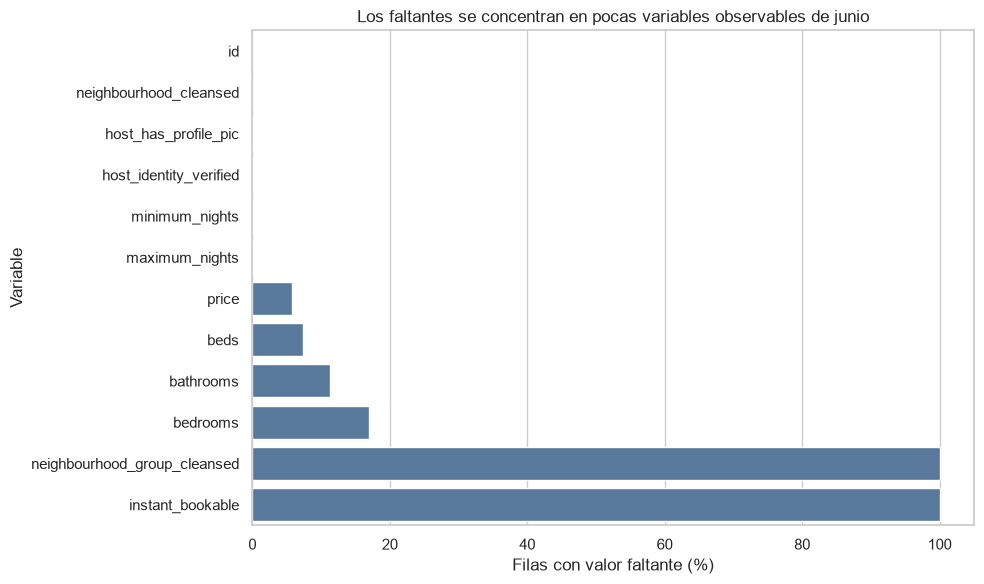

In [6]:
raw_for_missing = pd.read_csv(
    JUNE_PATH,
    compression='gzip',
    usecols=[
        'id', 'price', 'neighbourhood_cleansed', 'neighbourhood_group_cleansed',
        'property_type', 'room_type',
        'accommodates', 'bathrooms', 'bedrooms', 'beds', 'amenities',
        'minimum_nights', 'maximum_nights', 'instant_bookable',
        'host_has_profile_pic', 'host_identity_verified'
    ],
)
missingness = raw_for_missing.isna().sum().rename('nulos').to_frame()
missingness['porcentaje'] = 100 * missingness['nulos'] / len(raw_for_missing)
missingness = missingness.sort_values(['nulos', 'porcentaje'], ascending=False)
display(missingness)

fig, ax = plt.subplots(figsize=(10, 6))
plot_missing = missingness.head(12).sort_values('porcentaje')
sns.barplot(data=plot_missing, x='porcentaje', y=plot_missing.index, color='#4C78A8', ax=ax)
ax.set_title('Los faltantes se concentran en pocas variables observables de junio')
ax.set_xlabel('Filas con valor faltante (%)')
ax.set_ylabel('Variable')
fig.tight_layout()
fig.savefig(FIGURES / 'missingness_june.png', dpi=150, bbox_inches='tight')
plt.show()

## Precio de desarrollo

El precio tiene una escala positiva y puede presentar cola derecha. Por eso la transformación `log(precio)` será una candidata para la regresión futura, pero su ajuste y cualquier regla de extremos deben decidirse solo con desarrollo. Esta celda describe junio y no evalúa desempeño ni distribución del test.

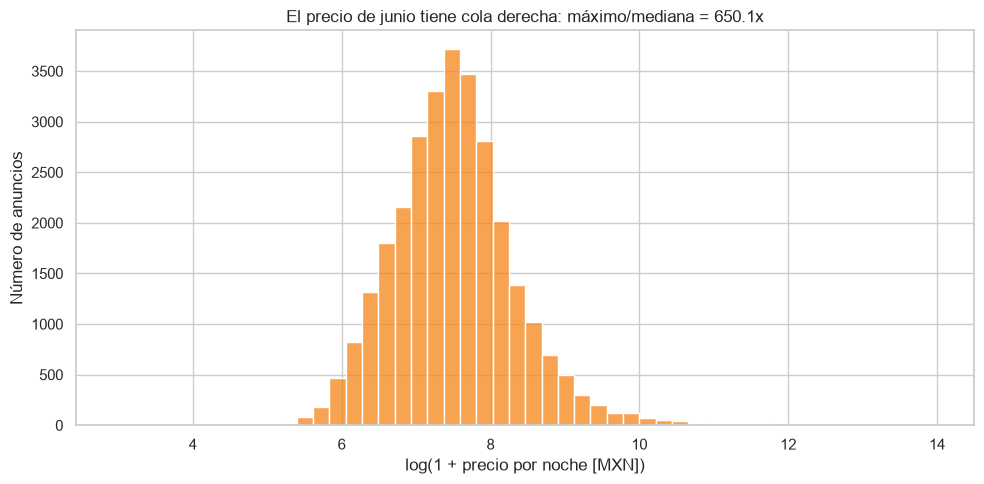

Mediana: $1,756.00 MXN; máximo: $1,141,520.00 MXN


In [7]:
median_price = df_dev['price_mxn'].median()
max_price = df_dev['price_mxn'].max()
fig, ax = plt.subplots(figsize=(10, 5))
sns.histplot(np.log1p(df_dev['price_mxn']), bins=50, color='#F58518', ax=ax)
ax.set_title(f'El precio de junio tiene cola derecha: máximo/mediana = {max_price / median_price:.1f}x')
ax.set_xlabel('log(1 + precio por noche [MXN])')
ax.set_ylabel('Número de anuncios')
fig.tight_layout()
fig.savefig(FIGURES / 'price_log_distribution_june.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Mediana: ${median_price:,.2f} MXN; máximo: ${max_price:,.2f} MXN')

## Precio por alcaldía

La alcaldía se resume con mediana y cuartiles, siempre mostrando el tamaño de grupo. El baseline propuesto podrá usar la mediana por alcaldía y tipo de alojamiento, pero grupos pequeños deberán tratarse con una regla de respaldo definida en desarrollo.

,n,mediana,q1,q3
neighbourhood_cleansed,,,,
Tláhuac,49,628.000,513.5300,838.3800
Milpa Alta,25,823.500,571.0000,1655.0000
Gustavo A. Madero,531,856.000,571.0000,1370.0000
Iztapalapa,356,881.000,627.6500,1369.4100
Azcapotzalco,399,970.000,634.0000,1544.5000
Venustiano Carranza,1022,1069.855,726.0300,1598.0000
Xochimilco,213,1129.770,684.0000,2453.5300
La Magdalena Contreras,135,1205.500,841.6800,2156.0000
Iztacalco,569,1222.000,797.0000,1825.0000


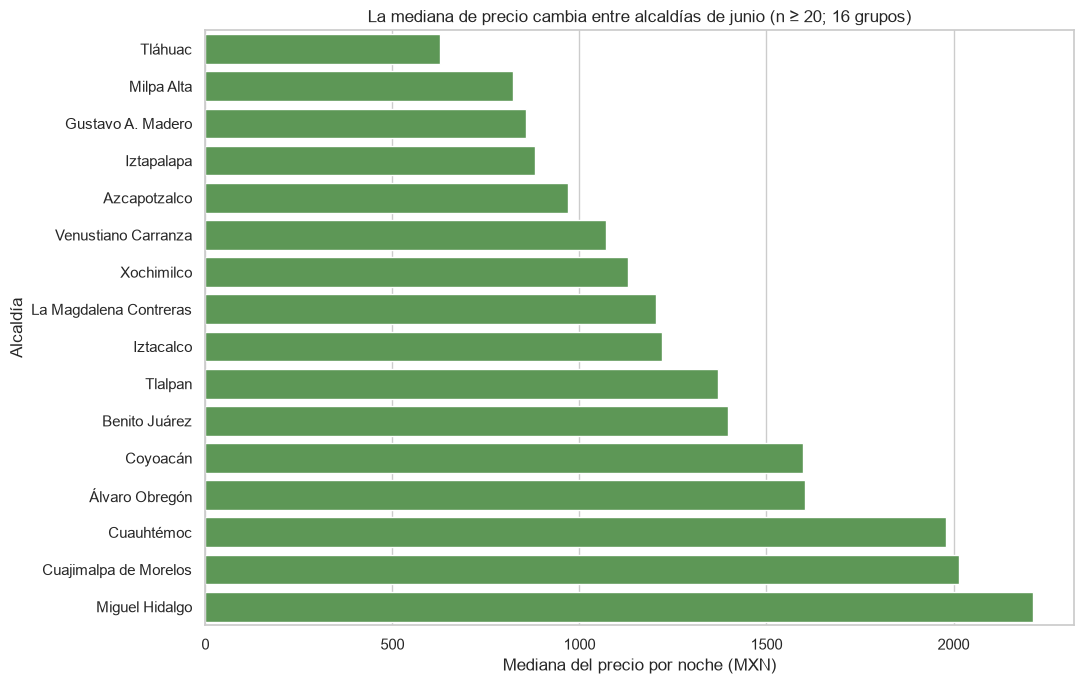

In [8]:
neighbourhood_summary = (
    df_dev.groupby('neighbourhood_cleansed', observed=True)['price_mxn']
    .agg(n='size', mediana='median', q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
    .query('n >= 20')
    .sort_values('mediana')
)
display(neighbourhood_summary)

fig, ax = plt.subplots(figsize=(11, 7))
sns.barplot(data=neighbourhood_summary.reset_index(), x='mediana', y='neighbourhood_cleansed', color='#54A24B', ax=ax)
ax.set_title(f'La mediana de precio cambia entre alcaldías de junio (n ≥ 20; {len(neighbourhood_summary)} grupos)')
ax.set_xlabel('Mediana del precio por noche (MXN)')
ax.set_ylabel('Alcaldía')
fig.tight_layout()
fig.savefig(FIGURES / 'price_by_neighbourhood_june.png', dpi=150, bbox_inches='tight')
plt.show()

## Precio por tipo de alojamiento y capacidad

El tipo de alojamiento y la capacidad representan decisiones conocidas por el anfitrión antes de publicar. Se comparan medianas con tamaños de grupo y se revisan `accommodates` y `bedrooms` como variables numéricas candidatas. Estas diferencias pueden justificar incluir efectos no lineales o transformaciones en modelos posteriores, sin seleccionar todavía un modelo.

,n,mediana,q1,q3
room_type,,,,
Shared room,291,503.0,382.180,718.0000
Private room,9407,970.0,667.835,1600.0000
Entire home/apt,19856,2163.0,1484.000,3356.8125
Hotel room,83,3132.0,1553.500,10076.5000


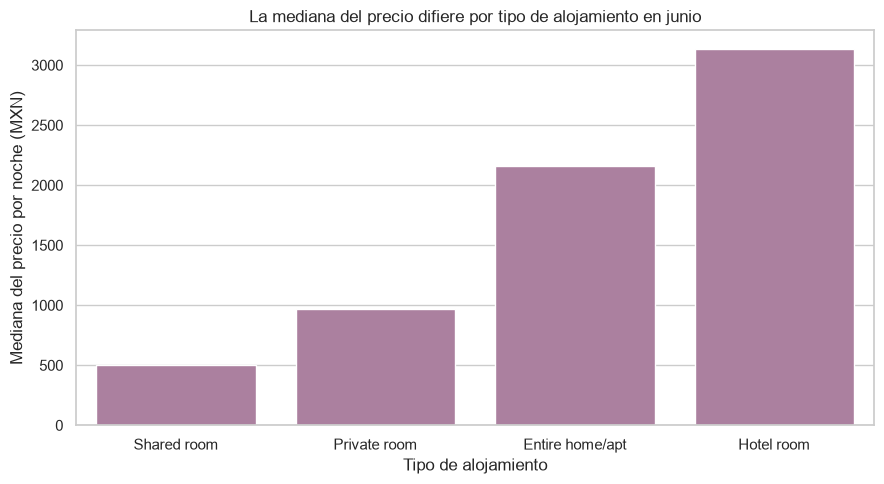

In [9]:
room_summary = (
    df_dev.groupby('room_type', observed=True)['price_mxn']
    .agg(n='size', mediana='median', q1=lambda s: s.quantile(0.25), q3=lambda s: s.quantile(0.75))
    .sort_values('mediana')
)
display(room_summary)

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=room_summary.reset_index(), x='room_type', y='mediana', color='#B279A2', ax=ax)
ax.set_title('La mediana del precio difiere por tipo de alojamiento en junio')
ax.set_xlabel('Tipo de alojamiento')
ax.set_ylabel('Mediana del precio por noche (MXN)')
fig.tight_layout()
fig.savefig(FIGURES / 'price_by_room_type_june.png', dpi=150, bbox_inches='tight')
plt.show()

,n,mediana
accommodates,,
1.0,2548,685.00
2.0,11993,1370.00
3.0,2793,1753.50
4.0,6459,2214.00
5.0,1621,2404.00
6.0,2236,3081.50
7.0,368,3224.11
8.0,640,4125.43
9.0,97,4108.50


,n,mediana
bedrooms,,
1.0,18801,1369.41
2.0,7649,2369.08
3.0,2173,3686.00
4.0,519,5280.00
5.0,179,6732.94
6.0,119,8102.50
7.0,54,9818.56
8.0,50,9557.00
9.0,22,13514.00


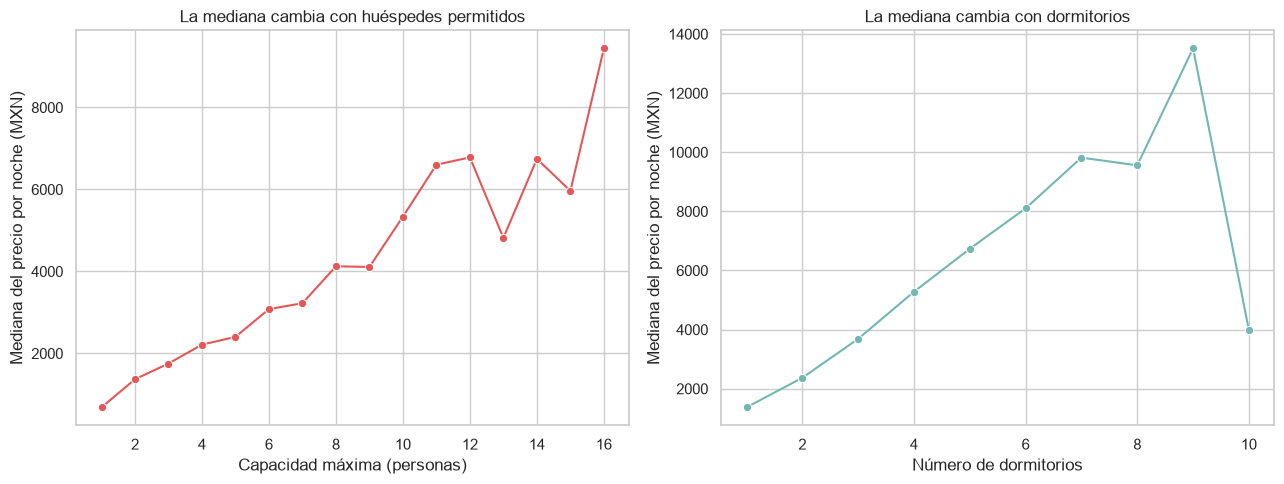

In [10]:
capacity_summary = (
    df_dev.groupby('accommodates', observed=True)['price_mxn']
    .agg(n='size', mediana='median')
    .query('n >= 20')
    .sort_index()
)
bedrooms_summary = (
    df_dev.groupby('bedrooms', observed=True)['price_mxn']
    .agg(n='size', mediana='median')
    .query('n >= 20')
    .sort_index()
)
display(capacity_summary)
display(bedrooms_summary)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.lineplot(data=capacity_summary.reset_index(), x='accommodates', y='mediana', marker='o', color='#E45756', ax=axes[0])
axes[0].set_title('La mediana cambia con huéspedes permitidos')
axes[0].set_xlabel('Capacidad máxima (personas)')
axes[0].set_ylabel('Mediana del precio por noche (MXN)')
sns.lineplot(data=bedrooms_summary.reset_index(), x='bedrooms', y='mediana', marker='o', color='#72B7B2', ax=axes[1])
axes[1].set_title('La mediana cambia con dormitorios')
axes[1].set_xlabel('Número de dormitorios')
axes[1].set_ylabel('Mediana del precio por noche (MXN)')
fig.tight_layout()
fig.savefig(FIGURES / 'price_by_capacity_bedrooms_june.png', dpi=150, bbox_inches='tight')
plt.show()

## Hallazgos y decisiones de modelado

- El desarrollo tiene anuncios con precio válido después de excluir únicamente objetivos faltantes o no válidos; la cantidad exacta queda en el log y no se sustituye por datos de septiembre.
- La escala del precio y su cola derecha justifican evaluar `log(precio)` en la regresión, manteniendo también MAE en MXN para interpretar el error.
- La variación por alcaldía y tipo de alojamiento respalda el baseline de mediana por ambos grupos, con respaldo para categorías pequeñas.
- Capacidad y dormitorios se mantienen como candidatos numéricos; la forma de sus relaciones se debe validar en desarrollo con transformaciones o términos no lineales, sin mirar el test.
- Los extremos no se eliminan automáticamente. Se conserva la trazabilidad y se deja como decisión pendiente una sensibilidad de modelado basada exclusivamente en junio.

## Limitaciones

Este EDA es descriptivo y no identifica causalidad. El snapshot no observa la fecha real de publicación, la demanda ni los costos del anfitrión. El precio en el export no trae una columna explícita de moneda; la interpretación en MXN se documenta con la procedencia oficial y el contexto de Ciudad de México. Las variables de reseñas, ratings, disponibilidad observada, ingresos estimados, derivados del precio e identificadores quedan fuera de los predictores por disponibilidad temporal o fuga. El test permanece reservado para la evaluación final de una sola vez.